In [2]:
import  pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import openpyxl
from sklearn.linear_model import  LinearRegression

In [3]:
df = pd.read_csv("synthetic_employee_burnout.csv")

In [4]:
df

,Name,Age,Gender,JobRole,Experience,WorkHoursPerWeek,RemoteRatio,SatisfactionLevel,StressLevel,Burnout
0,Max Ivanov,32,Male,Analyst,3,60,21,4.40,1,0
1,Max Wang,40,Female,Engineer,9,47,67,2.09,2,0
2,Nina Petrov,33,Female,Engineer,2,44,20,2.58,3,0
3,John Ivanov,35,Female,Manager,6,44,70,3.23,8,0
4,John Wang,59,Male,Sales,8,38,46,4.41,1,0
...,...,...,...,...,...,...,...,...,...,...
1995,Leo Brown,41,Female,Manager,4,63,17,3.40,4,0
1996,Alex Brown,23,Female,HR,2,39,20,4.67,9,0
1997,Nina Wang,31,Female,HR,10,39,4,4.10,4,0
1998,Kate Lee,25,Male,HR,0,40,57,2.11,4,0


In [5]:
df["WorkHoursPerWeek"] = df["WorkHoursPerWeek"].astype(int)
print(df["WorkHoursPerWeek"].dtype)

int64


In [6]:
df1 = df[(df['Age'] > 30) & (df['Age'] < 50)].copy()

In [7]:
df1.iloc[0:1999]

,Name,Age,Gender,JobRole,Experience,WorkHoursPerWeek,RemoteRatio,SatisfactionLevel,StressLevel,Burnout
0,Max Ivanov,32,Male,Analyst,3,60,21,4.40,1,0
1,Max Wang,40,Female,Engineer,9,47,67,2.09,2,0
2,Nina Petrov,33,Female,Engineer,2,44,20,2.58,3,0
3,John Ivanov,35,Female,Manager,6,44,70,3.23,8,0
5,Lily Smith,45,Female,Sales,11,44,90,4.31,7,0
...,...,...,...,...,...,...,...,...,...,...
1991,Dina Wang,37,Female,Manager,12,58,70,4.68,6,0
1993,Lily Brown,45,Male,Analyst,0,32,32,3.78,10,0
1995,Leo Brown,41,Female,Manager,4,63,17,3.40,4,0
1997,Nina Wang,31,Female,HR,10,39,4,4.10,4,0


In [8]:
dup = df1['Name'].unique()
print(dup)

<ArrowStringArray>
[  'Max Ivanov',     'Max Wang',  'Nina Petrov',  'John Ivanov',
   'Lily Smith',   'Max Garcia',    'Ivan Chen',    'Ivan Wang',
   'John Brown',  'Dina Petrov',  'Lily Garcia',    'Kate Wang',
  'John Petrov',  'Kate Garcia',      'Max Kim',    'Dina Wang',
    'Kate Chen',   'Nina Brown',   'John Smith',     'Alex Kim',
     'Leo Chen', 'Lily Johnson',     'Kate Kim',    'John Wang',
  'Alex Petrov',   'Sam Garcia',   'Dina Brown',     'Nina Lee',
 'Ivan Johnson',    'Sam Brown', 'Alex Johnson',    'Max Brown',
      'Sam Kim',  'Nina Garcia',  'Kate Petrov',     'Alex Lee',
  'Lily Petrov',    'Alex Wang',    'Lily Chen',  'Alex Ivanov',
   'Max Petrov',  'John Garcia',   'Leo Garcia',     'Ivan Kim',
     'Max Chen',    'Max Smith',  'Ivan Garcia',    'John Chen',
 'John Johnson',   'Ivan Brown',     'John Kim', 'Kate Johnson',
     'Kate Lee',  'Dina Ivanov',    'Nina Chen',    'Dina Chen',
  'Sam Johnson',      'Sam Lee',   'Nina Smith',     'Leo Wang',
    'N

In [9]:
df1 = df1.sort_values(by = 'Experience', ascending = False )

In [10]:
df1

,Name,Age,Gender,JobRole,Experience,WorkHoursPerWeek,RemoteRatio,SatisfactionLevel,StressLevel,Burnout
1844,Kate Lee,49,Male,Sales,28,55,24,4.12,2,0
904,Alex Lee,49,Female,Engineer,28,34,41,1.89,7,0
1801,Max Petrov,49,Male,Analyst,28,47,18,1.93,9,0
677,Lily Smith,49,Male,HR,28,59,69,4.92,4,0
743,Sam Lee,49,Male,Engineer,27,55,98,2.32,4,0
...,...,...,...,...,...,...,...,...,...,...
1932,Lily Brown,38,Male,Engineer,0,38,40,4.10,9,0
64,Dina Brown,44,Male,Manager,0,44,41,2.63,9,0
1993,Lily Brown,45,Male,Analyst,0,32,32,3.78,10,0
1949,Nina Wang,43,Female,Analyst,0,64,69,3.52,1,0


In [11]:
df1['Employee ID'] = range(1,len(df1)+1)

In [12]:
df1

,Name,Age,Gender,JobRole,Experience,WorkHoursPerWeek,RemoteRatio,SatisfactionLevel,StressLevel,Burnout,Employee ID
1844,Kate Lee,49,Male,Sales,28,55,24,4.12,2,0,1
904,Alex Lee,49,Female,Engineer,28,34,41,1.89,7,0,2
1801,Max Petrov,49,Male,Analyst,28,47,18,1.93,9,0,3
677,Lily Smith,49,Male,HR,28,59,69,4.92,4,0,4
743,Sam Lee,49,Male,Engineer,27,55,98,2.32,4,0,5
...,...,...,...,...,...,...,...,...,...,...,...
1932,Lily Brown,38,Male,Engineer,0,38,40,4.10,9,0,978
64,Dina Brown,44,Male,Manager,0,44,41,2.63,9,0,979
1993,Lily Brown,45,Male,Analyst,0,32,32,3.78,10,0,980
1949,Nina Wang,43,Female,Analyst,0,64,69,3.52,1,0,981


In [13]:
df1.set_index('Employee ID')

,Name,Age,Gender,JobRole,Experience,WorkHoursPerWeek,RemoteRatio,SatisfactionLevel,StressLevel,Burnout
Employee ID,,,,,,,,,,
1,Kate Lee,49,Male,Sales,28,55,24,4.12,2,0
2,Alex Lee,49,Female,Engineer,28,34,41,1.89,7,0
3,Max Petrov,49,Male,Analyst,28,47,18,1.93,9,0
4,Lily Smith,49,Male,HR,28,59,69,4.92,4,0
5,Sam Lee,49,Male,Engineer,27,55,98,2.32,4,0
...,...,...,...,...,...,...,...,...,...,...
978,Lily Brown,38,Male,Engineer,0,38,40,4.10,9,0
979,Dina Brown,44,Male,Manager,0,44,41,2.63,9,0
980,Lily Brown,45,Male,Analyst,0,32,32,3.78,10,0


In [14]:
 df50 = df1[(df1['Employee ID'] >= 1) & (df1['Employee ID'] <= 50)]

In [15]:
df50.set_index('Employee ID')

,Name,Age,Gender,JobRole,Experience,WorkHoursPerWeek,RemoteRatio,SatisfactionLevel,StressLevel,Burnout
Employee ID,,,,,,,,,,
1,Kate Lee,49,Male,Sales,28,55,24,4.12,2,0
2,Alex Lee,49,Female,Engineer,28,34,41,1.89,7,0
3,Max Petrov,49,Male,Analyst,28,47,18,1.93,9,0
4,Lily Smith,49,Male,HR,28,59,69,4.92,4,0
5,Sam Lee,49,Male,Engineer,27,55,98,2.32,4,0
6,Kate Lee,48,Male,HR,27,43,5,4.17,3,0
7,Lily Lee,48,Male,HR,27,51,64,1.67,6,0
8,Leo Garcia,49,Female,Sales,27,44,22,3.54,8,0
9,Max Wang,49,Female,Engineer,27,56,39,2.63,10,1


In [16]:
K = df50[0:10]

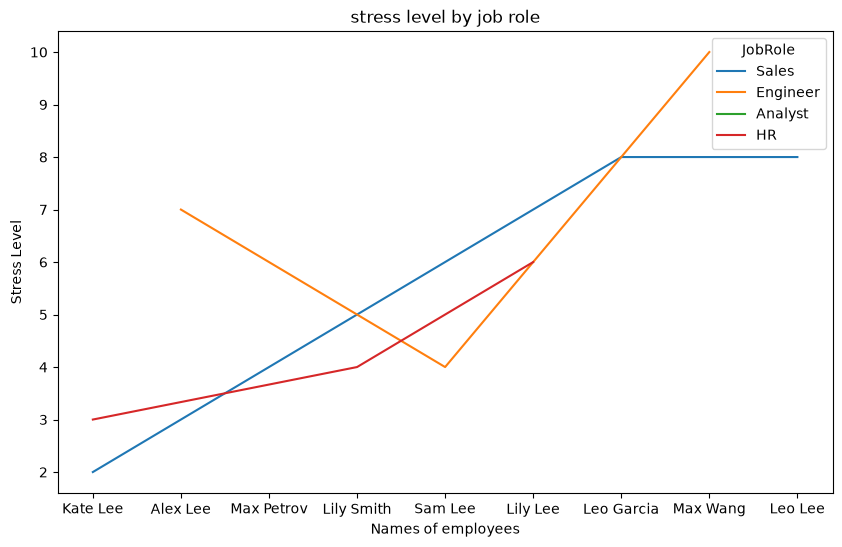

In [17]:
plt.figure(figsize= (10,6))
sns.lineplot(data = K, x = 'Name', y = 'StressLevel',hue = 'JobRole')

plt.title('stress level by job role')
plt.ylabel('Stress Level')
plt.xlabel('Names of employees')
plt.show()


In [18]:
k = df1[df1['Gender'] == 'Male'].groupby('JobRole').agg({'StressLevel': 'mean'})

In [19]:
k

,StressLevel
JobRole,
Analyst,5.404959
Engineer,5.229167
HR,5.558442
Manager,4.919192
Sales,5.829545


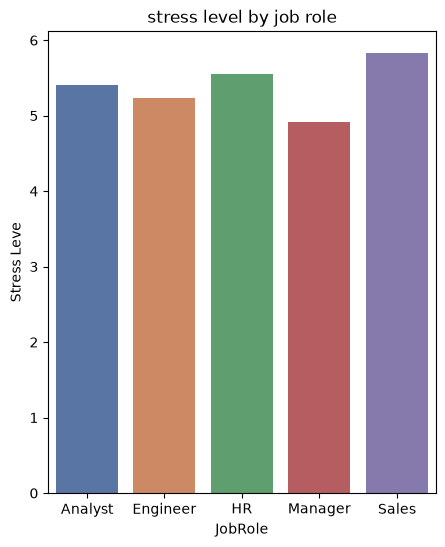

In [20]:
plt.figure(figsize= (5,6))
sns.barplot(data = k, x = 'JobRole', y = 'StressLevel',hue = 'JobRole',palette='deep')

plt.title('stress level by job role')
plt.ylabel('Stress Leve')
plt.show()



In [21]:
J = df1[df1['Gender'] == 'Male'].groupby('JobRole').agg({'WorkHoursPerWeek': 'mean',
                                                          'SatisfactionLevel': 'mean'})
Male = J

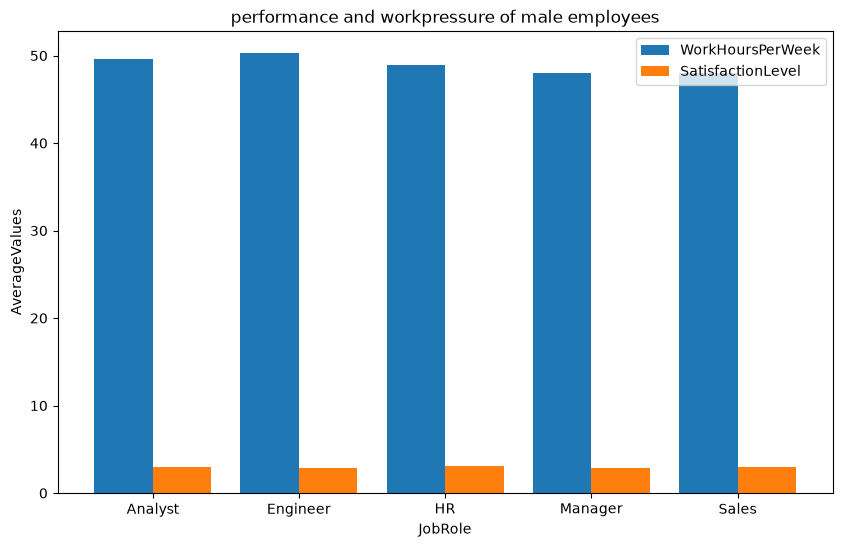

In [22]:

J.plot(kind = 'bar',
       figsize = (10,6),
       width = 0.8)


plt.title('performance and workpressure of male employees')
plt.xlabel('JobRole')
plt.ylabel('AverageValues')
legend = (['WorkHoursPerWeek','SatisfactionLevel'])
plt.xticks(rotation = 0)
plt.show()

In [23]:
B = df1.groupby(['Gender','JobRole']).agg({'WorkHoursPerWeek': 'mean',
                                                          'StressLevel': 'mean'})
print(B.index)

MultiIndex([('Female',  'Analyst'),
            ('Female', 'Engineer'),
            ('Female',       'HR'),
            ('Female',  'Manager'),
            ('Female',    'Sales'),
            (  'Male',  'Analyst'),
            (  'Male', 'Engineer'),
            (  'Male',       'HR'),
            (  'Male',  'Manager'),
            (  'Male',    'Sales')],
           names=['Gender', 'JobRole'])


In [24]:
B = round(B.reset_index(),2)
print(B.index)
B

RangeIndex(start=0, stop=10, step=1)


,Gender,JobRole,WorkHoursPerWeek,StressLevel
0,Female,Analyst,47.74,5.26
1,Female,Engineer,49.90,4.95
2,Female,HR,48.54,5.49
3,Female,Manager,50.20,5.33
4,Female,Sales,48.51,5.34
5,Male,Analyst,49.62,5.40
6,Male,Engineer,50.29,5.23
7,Male,HR,48.94,5.56
8,Male,Manager,48.03,4.92
9,Male,Sales,47.98,5.83


In [25]:

Stress = B.melt(id_vars = ['Gender','JobRole'], value_vars = ['WorkHoursPerWeek', 'StressLevel'],var_name = 'Parameter', value_name = 'Average')
Stress['Group'] = Stress['Gender'] + ' - ' + Stress['Parameter'] #this to add two diff hue seperately

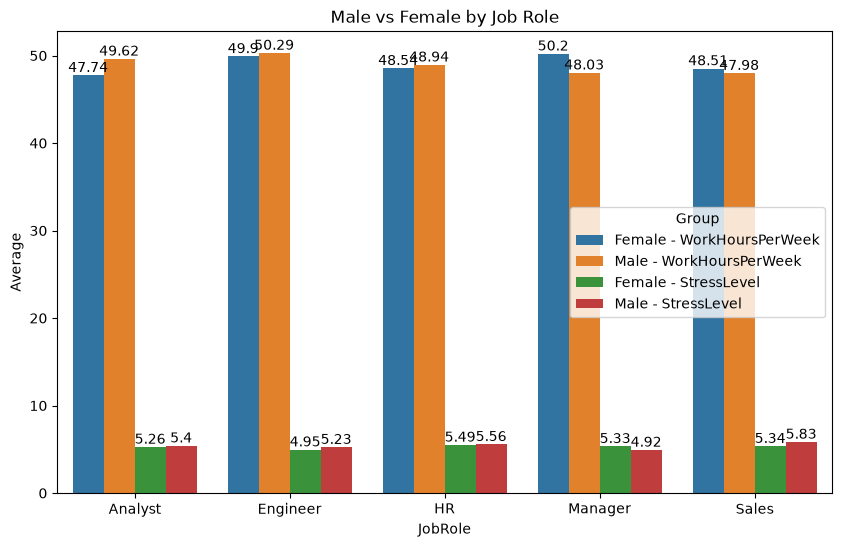

In [26]:
plt.figure(figsize= (10,6))
ax = sns.barplot(data = Stress,
            x = 'JobRole',
            y = 'Average',
            hue = 'Group'
           )
for container in ax.containers:
    ax.bar_label(container)
plt.title('Male vs Female by Job Role')
plt.show()

Text(0.5, 1.03, 'Male vs Female by Job Role')

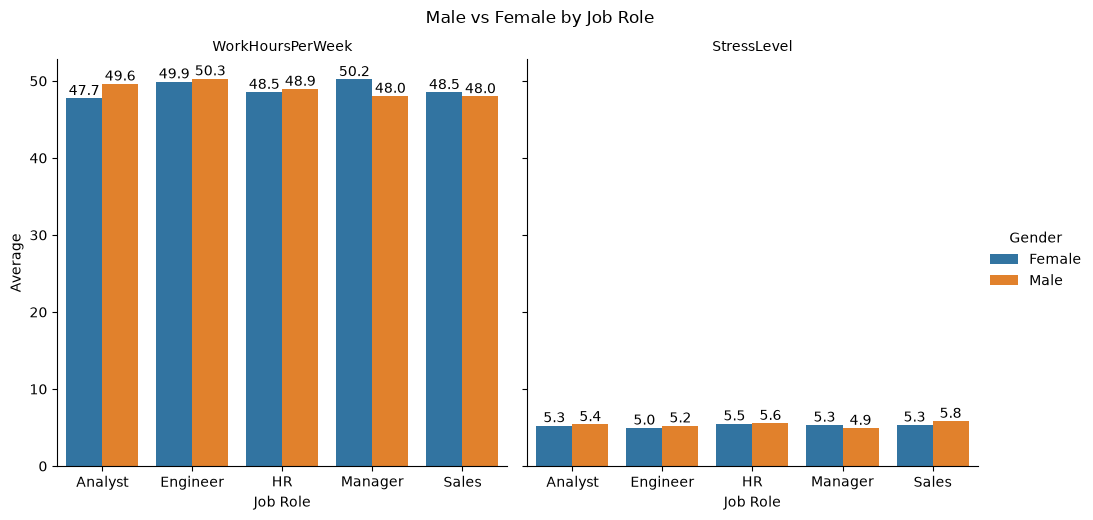

In [27]:
ax = sns.catplot(
    data=Stress,
    x='JobRole',
    y='Average',
    hue='Gender',
    col='Parameter',
    kind='bar',
    height=5,
    aspect=1
)
for subplot in ax.axes.flat:
    for container in subplot.containers:
        subplot.bar_label(container, fmt='%.1f')

ax.set_axis_labels('Job Role', 'Average')
ax.set_titles('{col_name}')
ax.fig.suptitle('Male vs Female by Job Role', y=1.03)

In [28]:
B[B['JobRole'].isin(['Analyst','HR'])]

,Gender,JobRole,WorkHoursPerWeek,StressLevel
0,Female,Analyst,47.74,5.26
2,Female,HR,48.54,5.49
5,Male,Analyst,49.62,5.40
7,Male,HR,48.94,5.56


In [29]:
df50.dtypes

Name                     str
Age                    int64
Gender                   str
JobRole                  str
Experience             int64
WorkHoursPerWeek       int64
RemoteRatio            int64
SatisfactionLevel    float64
StressLevel            int64
Burnout                int64
Employee ID            int64
dtype: object

In [30]:
A= df50[df50['WorkHoursPerWeek'] <= 50]

In [31]:
df50['WorkHoursPerWeek'] = df50['WorkHoursPerWeek'].astype(int) 

In [32]:
df

,Name,Age,Gender,JobRole,Experience,WorkHoursPerWeek,RemoteRatio,SatisfactionLevel,StressLevel,Burnout
0,Max Ivanov,32,Male,Analyst,3,60,21,4.40,1,0
1,Max Wang,40,Female,Engineer,9,47,67,2.09,2,0
2,Nina Petrov,33,Female,Engineer,2,44,20,2.58,3,0
3,John Ivanov,35,Female,Manager,6,44,70,3.23,8,0
4,John Wang,59,Male,Sales,8,38,46,4.41,1,0
...,...,...,...,...,...,...,...,...,...,...
1995,Leo Brown,41,Female,Manager,4,63,17,3.40,4,0
1996,Alex Brown,23,Female,HR,2,39,20,4.67,9,0
1997,Nina Wang,31,Female,HR,10,39,4,4.10,4,0
1998,Kate Lee,25,Male,HR,0,40,57,2.11,4,0


In [33]:
crosstab = pd.crosstab(df['Experience'],df['JobRole'])
crosstab

JobRole,Analyst,Engineer,HR,Manager,Sales
Experience,,,,,
0,30,32,28,41,35
1,30,34,36,36,37
2,30,26,33,32,29
3,31,19,23,26,25
4,25,26,20,25,21
5,23,22,23,16,20
6,21,16,15,16,17
7,20,15,17,24,10
8,20,21,19,16,17


In [34]:
k = df.select_dtypes(include = ['number']).columns

In [35]:
k

Index(['Age', 'Experience', 'WorkHoursPerWeek', 'RemoteRatio',
       'SatisfactionLevel', 'StressLevel', 'Burnout'],
      dtype='str')

In [36]:
correlation = round(df[['WorkHoursPerWeek','StressLevel']].corr(),3)
correlation

,WorkHoursPerWeek,StressLevel
WorkHoursPerWeek,1.000,-0.005
StressLevel,-0.005,1.000


In [37]:
import seaborn as sns

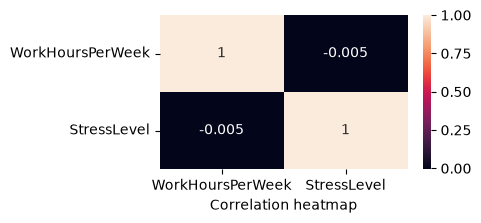

In [38]:
plt.figure(figsize = (4,2))
sns.heatmap(correlation, annot = True)
plt.xlabel("Correlation heatmap")
plt.show()

In [39]:
heat_map = pd.read_excel("Downloads/heatmap_data.xlsx")

In [40]:
heat_map


,EmployeeID,gender,department,Days Present,Accuracy of Work,Meeting Project Deadlines,Task Completion Rates,Interpersonal Skills Rating,Decision-Making Skills Rating,Sales Revenue Generated,churned
0,1,Male,Sales,20,High,Yes,85,8,7,51638,No
1,2,Female,Marketing,22,Medium,Yes,90,7,6,97797,Yes
2,3,Male,Human Resources,25,High,No,80,9,8,95341,No
3,4,Male,Engineering,19,Low,Yes,75,6,5,91806,No
4,5,Female,Finance,23,Medium,Yes,85,7,7,64247,Yes
5,6,Male,Sales,21,High,Yes,95,8,8,89988,No
6,7,Female,Marketing,24,Low,No,70,5,4,70934,Yes
7,8,Male,Human Resources,18,Medium,Yes,80,6,6,96578,No
8,9,Male,Engineering,20,High,Yes,90,8,7,74219,No
9,10,Female,Finance,22,Medium,Yes,85,7,6,87009,Yes


In [41]:
heat_map.select_dtypes(include = ['number']).columns

Index(['EmployeeID', 'Days Present', 'Task Completion Rates',
       'Interpersonal Skills Rating', 'Decision-Making Skills Rating',
       'Sales Revenue Generated'],
      dtype='str')

In [42]:
corr = round(heat_map[['Task Completion Rates','Decision-Making Skills Rating','Sales Revenue Generated']].corr(),3)

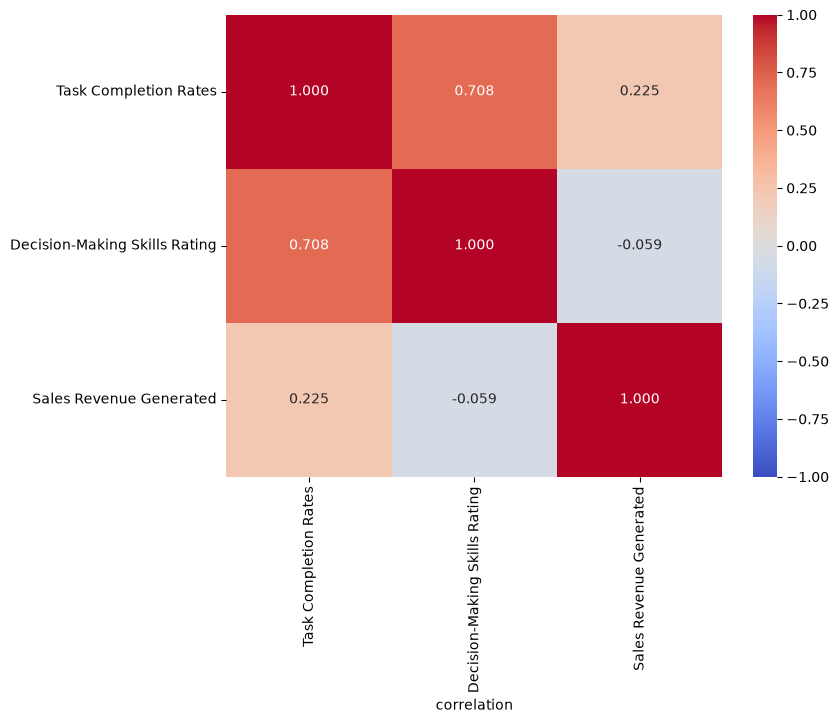

In [43]:
plt.figure(figsize = (8,6))
sns.heatmap(corr,annot = True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.3f')
plt.xlabel('correlation')
plt.show()

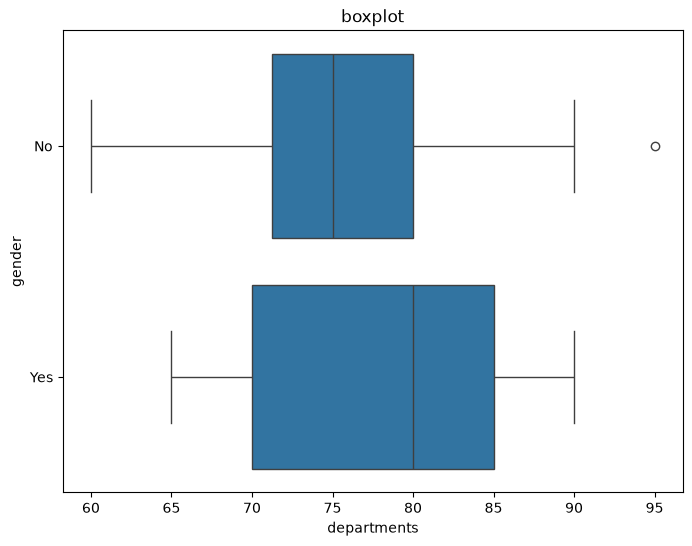

In [44]:
plt.figure(figsize = (8,6))
sns.boxplot(x= heat_map['Task Completion Rates'],y = heat_map['churned'] , data = heat_map)
plt.title('boxplot')
plt.xlabel('departments')
plt.ylabel('gender')
plt.show()

In [45]:
data = pd.read_excel("Downloads/practice_data.xlsx")
data

,EmployeeID,gender,department,Days Present,Accuracy of Work,Meeting Project Deadlines,Task Completion Rates,Interpersonal Skills Rating,Decision-Making Skills Rating,Sales Revenue Generated,churned
0,1,Male,Sales,20,High,Yes,85,8,7,51638,No
1,2,Female,Marketing,22,Medium,Yes,90,7,6,97797,Yes
2,3,Male,Human Resources,25,High,No,80,9,8,95341,No
3,4,Male,Engineering,19,Low,Yes,75,6,5,91806,No
4,5,Female,Finance,23,Medium,Yes,85,7,7,64247,Yes
5,6,Male,Sales,21,High,Yes,95,8,8,89988,No
6,7,Female,Marketing,24,Low,No,70,5,4,70934,Yes
7,8,Male,Human Resources,18,Medium,Yes,80,6,6,96578,No
8,9,Male,Engineering,20,High,Yes,90,8,7,74219,No
9,10,Female,Finance,22,Medium,Yes,85,7,6,87009,Yes


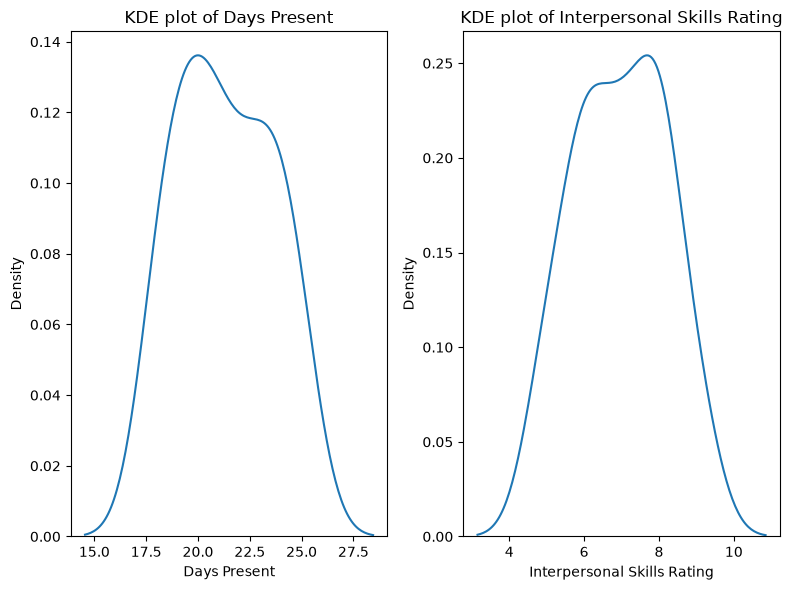

In [46]:
column_names = ['Days Present','Interpersonal Skills Rating']

fig,axes = plt.subplots(1,2, figsize = (8,6))

for Index, column in enumerate(column_names):
    sns.kdeplot(data[column], ax= axes[Index])
    axes[Index].set_title(f'KDE plot of {column}')

plt.tight_layout()
plt.show()

In [47]:
from scipy.stats import shapiro


In [48]:
column_names = ['Days Present','Sales Revenue Generated']
shapiro_result = {}
for column in column_names:
    stats, p_value = shapiro(data[column])
    shapiro_result[column] = round(p_value,3)

shapiro_result
    



{'Days Present': np.float64(0.044),
 'Sales Revenue Generated': np.float64(0.12)}

In [49]:
def sqrt_transformation(data, column_name):
    data[f'{column_name}_sqrt'] = np.sqrt( data[column_name])
    stat, p_value = shapiro(data[f'{column_name}_sqrt'])
    kdeplot = sns.kdeplot(data[f'{column_name}_sqrt'])
    print('p value:', round( p_value,3))
    print(kdeplot)

p value: 0.013
Axes(0.125,0.11;0.775x0.77)


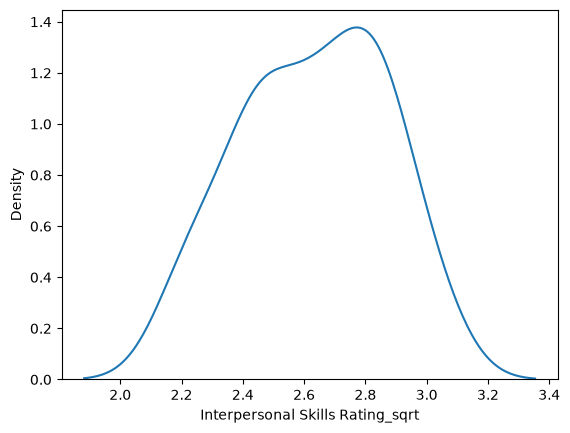

In [50]:
sqrt_transformation(data,'Interpersonal Skills Rating')

In [51]:
data.head()

,EmployeeID,gender,department,Days Present,Accuracy of Work,Meeting Project Deadlines,Task Completion Rates,Interpersonal Skills Rating,Decision-Making Skills Rating,Sales Revenue Generated,churned,Interpersonal Skills Rating_sqrt
0,1,Male,Sales,20,High,Yes,85,8,7,51638,No,2.828427
1,2,Female,Marketing,22,Medium,Yes,90,7,6,97797,Yes,2.645751
2,3,Male,Human Resources,25,High,No,80,9,8,95341,No,3.000000
3,4,Male,Engineering,19,Low,Yes,75,6,5,91806,No,2.449490
4,5,Female,Finance,23,Medium,Yes,85,7,7,64247,Yes,2.645751


In [52]:
from scipy import stats

In [53]:
pd.crosstab?

Signature:
pd.crosstab(
    index,
    columns,
    values=None,
    rownames=None,
    colnames=None,
    aggfunc=None,
    margins: 'bool' = False,
    margins_name: 'Hashable' = 'All',
    dropna: 'bool' = True,
    normalize: "bool | Literal[0, 1, 'all', 'index', 'columns']" = False,
) -> 'DataFrame'
Docstring:
Compute a simple cross tabulation of two (or more) factors.

By default, computes a frequency table of the factors unless an
array of values and an aggregation function are passed.

Parameters
----------
index : array-like, Series, or list of arrays/Series
    Values to group by in the rows.
columns : array-like, Series, or list of arrays/Series
    Values to group by in the columns.
values : array-like, optional
    Array of values to aggregate according to the factors.
    Requires `aggfunc` be specified.
rownames : sequence, default None
    If passed, must match number of row arrays passed.
colnames : sequence, default None
    If passed, must match number of column arra

In [54]:
from scipy.stats import pearsonr

In [55]:
DP = data['Days Present']
TCR = data['Task Completion Rates']
corr,p_value = stats.pearsonr(DP,TCR)
print(round(corr,2))


-0.12


In [56]:
import statsmodels.api as sm

x = data['Days Present']

y = data['Task Completion Rates']

x_constant = sm.add_constant(x)

model = sm.OLS(y,x_constant).fit()

print(model.summary())

                              OLS Regression Results                             
Dep. Variable:     Task Completion Rates   R-squared:                       0.015
Model:                               OLS   Adj. R-squared:                 -0.019
Method:                    Least Squares   F-statistic:                    0.4447
Date:                   Fri, 06 Nov 2026   Prob (F-statistic):              0.510
Time:                           20:20:19   Log-Likelihood:                -112.05
No. Observations:                     31   AIC:                             228.1
Df Residuals:                         29   BIC:                             231.0
Df Model:                              1                                         
Covariance Type:               nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const           87

In [57]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()
data['gender'] =  encoder.fit_transform(data['gender'])

data.head()

,EmployeeID,gender,department,Days Present,Accuracy of Work,Meeting Project Deadlines,Task Completion Rates,Interpersonal Skills Rating,Decision-Making Skills Rating,Sales Revenue Generated,churned,Interpersonal Skills Rating_sqrt
0,1,1,Sales,20,High,Yes,85,8,7,51638,No,2.828427
1,2,0,Marketing,22,Medium,Yes,90,7,6,97797,Yes,2.645751
2,3,1,Human Resources,25,High,No,80,9,8,95341,No,3.000000
3,4,1,Engineering,19,Low,Yes,75,6,5,91806,No,2.449490
4,5,0,Finance,23,Medium,Yes,85,7,7,64247,Yes,2.645751


In [58]:
data.columns

Index(['EmployeeID', 'gender', 'department', 'Days Present',
       'Accuracy of Work', 'Meeting Project Deadlines',
       'Task Completion Rates', 'Interpersonal Skills Rating',
       'Decision-Making Skills Rating', 'Sales Revenue Generated', 'churned',
       'Interpersonal Skills Rating_sqrt'],
      dtype='str')

In [60]:
from sklearn.model_selection import train_test_split
x_reg_train, x_reg_test, y_reg_train, y_reg_test =  train_test_split(x,y, test_size = 0.2,random_state = 42)

In [61]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
lr_model = LinearRegression()
lr_model.fit(x_reg_train,y_reg_train)

ValueError: Expected a 2-dimensional container but got <class 'pandas.Series'> instead. Pass a DataFrame containing a single row (i.e. single sample) or a single column (i.e. single feature) instead.

In [62]:
x_reg_train

24    20
12    23
0     20
4     23
16    20
5     21
13    21
11    19
22    24
1     22
2     25
25    19
3     19
21    21
26    23
18    25
30    20
20    23
7     18
10    25
14    24
28    24
19    19
6     24
Name: Days Present, dtype: int64

In [63]:
from sklearn.metrics import mean_squared_error

In [64]:
x = 2.36474

In [65]:
y = 3.34555

In [66]:
model = LinearRegression() 
model.fit(x, y) 
y_pred = model.predict(x) 
mape = mean_squared_error(y, y_pred) 
print("Mean squared error:", mape)

ValueError: Expected 2D array, got scalar array instead:
array=2.36474.
Reshape your data either using array.reshape(-1, 1) if your data has a single feature or array.reshape(1, -1) if it contains a single sample.

In [ ]:
sns.kdeplot(y_reg_train, label = "XkaData")
sns.kdeplot(y_reg_test,label = "YkaData")
plt.title("kuch bhi")
plt.show

In [67]:
round(data.groupby('gender')[['Task Completion Rates','Interpersonal Skills Rating','Interpersonal Skills Rating_sqrt']].mean(),2)

,Task Completion Rates,Interpersonal Skills Rating,Interpersonal Skills Rating_sqrt
gender,,,
0,77.69,6.85,2.61
1,76.94,7.06,2.65


In [68]:
Striker = pd.read_excel("Downloads/Strikers_performance.xlsx")
Striker

,Striker_ID,Nationality,Footedness,Marital Status,Goals Scored,Assists,Shots on Target,Shot Accuracy,Conversion Rate,Dribbling Success,Movement off the Ball,Hold-up Play,Aerial Duels Won,Defensive Contribution,Big Game Performance,Consistency,Penalty Success Rate,Impact on Team Performance,Off-field Conduct
0,1,Spain,Left-footed,No,17.483571,10.778533,34.795488,0.677836,0.166241,0.757061,50.921924,71.806409,15.682532,30.412215,6.152481,0.820314,0.922727,8.570370,11.451388
1,2,France,Left-footed,Yes,14.308678,13.728250,31.472436,0.544881,0.192774,0.796818,61.396150,53.726866,19.843983,26.474913,6.093172,0.803321,0.678984,3.444638,8.243689
2,3,Germany,Left-footed,No,18.238443,3.804297,25.417413,0.518180,0.160379,0.666869,65.863945,60.452227,20.090084,24.164116,3.408714,0.766540,0.843858,8.429491,9.506835
3,4,France,Right-footed,No,22.615149,9.688908,20.471443,0.599663,0.184602,0.638776,88.876877,60.511979,22.363152,44.129989,6.339820,0.611798,0.662997,6.532552,8.199653
4,5,France,Left-footed,Yes,13.829233,6.048072,29.887563,0.582982,0.105319,0.591485,75.565531,54.982158,13.165708,37.859323,8.465658,0.701638,0.906538,8.414915,6.665333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,496,England,Left-footed,Yes,17.694550,7.156699,39.042650,0.707015,0.240660,0.707748,89.351540,60.284576,28.386885,39.510350,4.448635,0.767147,0.770213,5.999478,12.419711
496,497,Germany,Right-footed,Yes,9.813769,13.393060,39.430525,0.597348,0.186052,0.725775,78.155010,39.221882,15.974141,47.114106,6.742907,0.865265,0.876903,5.967767,8.653989
497,498,England,Left-footed,Yes,14.048307,9.922529,33.458564,0.511813,0.186012,0.575824,69.519115,56.797022,25.384241,71.129102,5.696650,0.628260,0.747261,11.249112,6.329751
498,499,England,Right-footed,Yes,10.621909,6.286463,32.168438,0.583693,0.239519,0.733418,68.168495,76.433782,9.151613,48.080362,2.611235,0.796795,0.799489,1.452370,11.305826


In [69]:
print(Striker.dtypes)

Striker_ID                      int64
Nationality                       str
Footedness                        str
Marital Status                    str
Goals Scored                  float64
Assists                       float64
Shots on Target               float64
Shot Accuracy                 float64
Conversion Rate               float64
Dribbling Success             float64
Movement off the Ball         float64
Hold-up Play                  float64
Aerial Duels Won              float64
Defensive Contribution        float64
Big Game Performance          float64
Consistency                   float64
Penalty Success Rate          float64
Impact on Team Performance    float64
Off-field Conduct             float64
dtype: object


In [70]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy = 'median')
columns = ['Big Game Performance','Penalty Success Rate','Movement off the Ball']
imputer.fit(Striker[columns])
Striker[columns] = imputer.transform(Striker[columns])

In [71]:
missing_values = Striker.isna().sum()
missing_values 

Striker_ID                    0
Nationality                   0
Footedness                    0
Marital Status                0
Goals Scored                  0
Assists                       0
Shots on Target               0
Shot Accuracy                 0
Conversion Rate               0
Dribbling Success             0
Movement off the Ball         0
Hold-up Play                  0
Aerial Duels Won              0
Defensive Contribution        0
Big Game Performance          0
Consistency                   0
Penalty Success Rate          0
Impact on Team Performance    0
Off-field Conduct             0
dtype: int64

In [72]:
stats, p_value = shapiro(Striker['Consistency'])
shapiro_pvalue = round(p_value,2)
shapiro_pvalue

np.float64(0.45)

In [73]:
round(Striker.describe(),2)

,Striker_ID,Goals Scored,Assists,Shots on Target,Shot Accuracy,Conversion Rate,Dribbling Success,Movement off the Ball,Hold-up Play,Aerial Duels Won,Defensive Contribution,Big Game Performance,Consistency,Penalty Success Rate,Impact on Team Performance,Off-field Conduct
count,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00
mean,250.50,15.04,8.10,25.76,0.60,0.20,0.70,69.79,59.81,19.53,39.95,6.93,0.74,0.80,7.01,8.06
std,144.48,4.90,2.93,7.07,0.10,0.05,0.10,10.34,10.17,4.96,9.92,1.94,0.10,0.10,2.10,2.07
min,1.00,0.00,0.00,4.73,0.31,0.05,0.40,40.71,35.07,4.96,8.23,2.23,0.46,0.53,0.56,0.62
25%,125.75,11.50,6.21,20.78,0.54,0.17,0.64,62.70,52.43,16.40,33.46,5.69,0.68,0.72,5.66,6.62
50%,250.50,15.06,8.09,25.84,0.60,0.20,0.70,69.62,60.08,19.74,39.98,6.91,0.75,0.80,6.99,8.02
75%,375.25,18.18,9.95,30.28,0.67,0.23,0.76,76.93,66.03,22.86,46.69,8.13,0.81,0.87,8.43,9.45
max,500.00,34.26,15.90,43.21,0.92,0.36,1.00,98.68,92.43,34.07,71.13,12.87,1.00,1.00,13.24,13.73


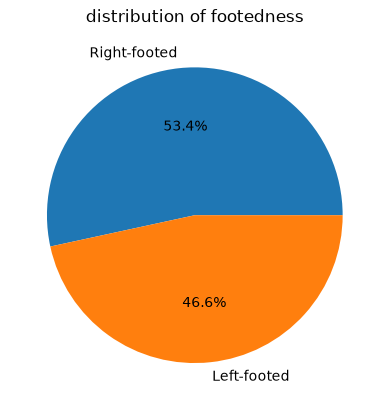

In [74]:
Striker['Footedness'].value_counts().plot(kind = 'pie', autopct = '%1.1f%%')
plt.title('distribution of footedness')
plt.show()

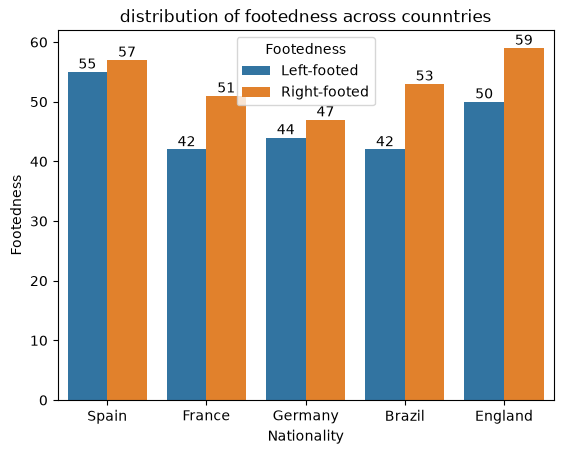

In [75]:
ax = sns.countplot(data = Striker, x = 'Nationality',hue = 'Footedness')
for container in ax.containers:
    ax.bar_label(container)
plt.title('distribution of footedness across counntries')
plt.xlabel('Nationality')
plt.ylabel('Footedness')
plt.show;

In [76]:
K = Striker.groupby(['Nationality']).agg({'Goals Scored': 'mean'})
M = Striker.groupby(['Footedness']).agg({'Conversion Rate': 'mean'})

M

,Conversion Rate
Footedness,
Left-footed,0.198086
Right-footed,0.200592


In [77]:
Z = Striker[Striker['Footedness'] == 'Left-footed']
Z.groupby('Nationality').agg({'Footedness':'count'})


,Footedness
Nationality,
Brazil,42
England,50
France,42
Germany,44
Spain,55


In [78]:
Striker.loc[Striker['Footedness'] == 'Left-footed', 'Nationality'].value_counts()

Nationality
Spain      55
England    50
Germany    44
France     42
Brazil     42
Name: count, dtype: int64

In [79]:
K  = Striker[Striker['Goals Scored'] == 34.26365745327361]
Striker

,Striker_ID,Nationality,Footedness,Marital Status,Goals Scored,Assists,Shots on Target,Shot Accuracy,Conversion Rate,Dribbling Success,Movement off the Ball,Hold-up Play,Aerial Duels Won,Defensive Contribution,Big Game Performance,Consistency,Penalty Success Rate,Impact on Team Performance,Off-field Conduct
0,1,Spain,Left-footed,No,17.483571,10.778533,34.795488,0.677836,0.166241,0.757061,50.921924,71.806409,15.682532,30.412215,6.152481,0.820314,0.922727,8.570370,11.451388
1,2,France,Left-footed,Yes,14.308678,13.728250,31.472436,0.544881,0.192774,0.796818,61.396150,53.726866,19.843983,26.474913,6.093172,0.803321,0.678984,3.444638,8.243689
2,3,Germany,Left-footed,No,18.238443,3.804297,25.417413,0.518180,0.160379,0.666869,65.863945,60.452227,20.090084,24.164116,3.408714,0.766540,0.843858,8.429491,9.506835
3,4,France,Right-footed,No,22.615149,9.688908,20.471443,0.599663,0.184602,0.638776,88.876877,60.511979,22.363152,44.129989,6.339820,0.611798,0.662997,6.532552,8.199653
4,5,France,Left-footed,Yes,13.829233,6.048072,29.887563,0.582982,0.105319,0.591485,75.565531,54.982158,13.165708,37.859323,8.465658,0.701638,0.906538,8.414915,6.665333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,496,England,Left-footed,Yes,17.694550,7.156699,39.042650,0.707015,0.240660,0.707748,89.351540,60.284576,28.386885,39.510350,4.448635,0.767147,0.770213,5.999478,12.419711
496,497,Germany,Right-footed,Yes,9.813769,13.393060,39.430525,0.597348,0.186052,0.725775,78.155010,39.221882,15.974141,47.114106,6.742907,0.865265,0.876903,5.967767,8.653989
497,498,England,Left-footed,Yes,14.048307,9.922529,33.458564,0.511813,0.186012,0.575824,69.519115,56.797022,25.384241,71.129102,5.696650,0.628260,0.747261,11.249112,6.329751
498,499,England,Right-footed,Yes,10.621909,6.286463,32.168438,0.583693,0.239519,0.733418,68.168495,76.433782,9.151613,48.080362,2.611235,0.796795,0.799489,1.452370,11.305826


In [80]:
K

,Striker_ID,Nationality,Footedness,Marital Status,Goals Scored,Assists,Shots on Target,Shot Accuracy,Conversion Rate,Dribbling Success,Movement off the Ball,Hold-up Play,Aerial Duels Won,Defensive Contribution,Big Game Performance,Consistency,Penalty Success Rate,Impact on Team Performance,Off-field Conduct
209,210,Spain,Right-footed,Yes,34.263657,13.089369,37.247037,0.502547,0.199965,0.856341,74.512253,60.39447,14.36973,39.612571,7.124663,0.939873,0.770955,9.309388,6.244765


In [81]:
N = round(Striker[['Hold-up Play','Consistency']].corr(),4)
N


,Hold-up Play,Consistency
Hold-up Play,1.000,0.145
Consistency,0.145,1.000


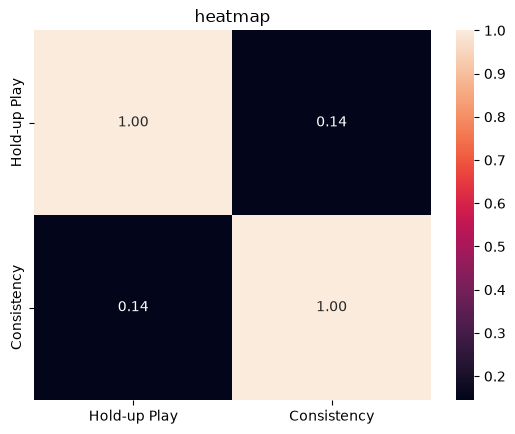

In [82]:
sns.heatmap(N,annot = True , fmt = '.2f')
plt.title('heatmap')
plt.show()

In [83]:
r,p_value = pearsonr(Striker['Hold-up Play'],Striker['Consistency'])
print(round(p_value,3))
print(round(r,3))
Striker

0.001
0.145


,Striker_ID,Nationality,Footedness,Marital Status,Goals Scored,Assists,Shots on Target,Shot Accuracy,Conversion Rate,Dribbling Success,Movement off the Ball,Hold-up Play,Aerial Duels Won,Defensive Contribution,Big Game Performance,Consistency,Penalty Success Rate,Impact on Team Performance,Off-field Conduct
0,1,Spain,Left-footed,No,17.483571,10.778533,34.795488,0.677836,0.166241,0.757061,50.921924,71.806409,15.682532,30.412215,6.152481,0.820314,0.922727,8.570370,11.451388
1,2,France,Left-footed,Yes,14.308678,13.728250,31.472436,0.544881,0.192774,0.796818,61.396150,53.726866,19.843983,26.474913,6.093172,0.803321,0.678984,3.444638,8.243689
2,3,Germany,Left-footed,No,18.238443,3.804297,25.417413,0.518180,0.160379,0.666869,65.863945,60.452227,20.090084,24.164116,3.408714,0.766540,0.843858,8.429491,9.506835
3,4,France,Right-footed,No,22.615149,9.688908,20.471443,0.599663,0.184602,0.638776,88.876877,60.511979,22.363152,44.129989,6.339820,0.611798,0.662997,6.532552,8.199653
4,5,France,Left-footed,Yes,13.829233,6.048072,29.887563,0.582982,0.105319,0.591485,75.565531,54.982158,13.165708,37.859323,8.465658,0.701638,0.906538,8.414915,6.665333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,496,England,Left-footed,Yes,17.694550,7.156699,39.042650,0.707015,0.240660,0.707748,89.351540,60.284576,28.386885,39.510350,4.448635,0.767147,0.770213,5.999478,12.419711
496,497,Germany,Right-footed,Yes,9.813769,13.393060,39.430525,0.597348,0.186052,0.725775,78.155010,39.221882,15.974141,47.114106,6.742907,0.865265,0.876903,5.967767,8.653989
497,498,England,Left-footed,Yes,14.048307,9.922529,33.458564,0.511813,0.186012,0.575824,69.519115,56.797022,25.384241,71.129102,5.696650,0.628260,0.747261,11.249112,6.329751
498,499,England,Right-footed,Yes,10.621909,6.286463,32.168438,0.583693,0.239519,0.733418,68.168495,76.433782,9.151613,48.080362,2.611235,0.796795,0.799489,1.452370,11.305826


In [84]:
Striker

,Striker_ID,Nationality,Footedness,Marital Status,Goals Scored,Assists,Shots on Target,Shot Accuracy,Conversion Rate,Dribbling Success,Movement off the Ball,Hold-up Play,Aerial Duels Won,Defensive Contribution,Big Game Performance,Consistency,Penalty Success Rate,Impact on Team Performance,Off-field Conduct
0,1,Spain,Left-footed,No,17.483571,10.778533,34.795488,0.677836,0.166241,0.757061,50.921924,71.806409,15.682532,30.412215,6.152481,0.820314,0.922727,8.570370,11.451388
1,2,France,Left-footed,Yes,14.308678,13.728250,31.472436,0.544881,0.192774,0.796818,61.396150,53.726866,19.843983,26.474913,6.093172,0.803321,0.678984,3.444638,8.243689
2,3,Germany,Left-footed,No,18.238443,3.804297,25.417413,0.518180,0.160379,0.666869,65.863945,60.452227,20.090084,24.164116,3.408714,0.766540,0.843858,8.429491,9.506835
3,4,France,Right-footed,No,22.615149,9.688908,20.471443,0.599663,0.184602,0.638776,88.876877,60.511979,22.363152,44.129989,6.339820,0.611798,0.662997,6.532552,8.199653
4,5,France,Left-footed,Yes,13.829233,6.048072,29.887563,0.582982,0.105319,0.591485,75.565531,54.982158,13.165708,37.859323,8.465658,0.701638,0.906538,8.414915,6.665333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,496,England,Left-footed,Yes,17.694550,7.156699,39.042650,0.707015,0.240660,0.707748,89.351540,60.284576,28.386885,39.510350,4.448635,0.767147,0.770213,5.999478,12.419711
496,497,Germany,Right-footed,Yes,9.813769,13.393060,39.430525,0.597348,0.186052,0.725775,78.155010,39.221882,15.974141,47.114106,6.742907,0.865265,0.876903,5.967767,8.653989
497,498,England,Left-footed,Yes,14.048307,9.922529,33.458564,0.511813,0.186012,0.575824,69.519115,56.797022,25.384241,71.129102,5.696650,0.628260,0.747261,11.249112,6.329751
498,499,England,Right-footed,Yes,10.621909,6.286463,32.168438,0.583693,0.239519,0.733418,68.168495,76.433782,9.151613,48.080362,2.611235,0.796795,0.799489,1.452370,11.305826


In [85]:
from scipy.stats import levene
from scipy.stats import f_oneway
Spain = Striker.query('Nationality == "Spain"')['Consistency']
France = Striker.query('Nationality == "France"')[ 'Consistency']
Germany = Striker.query('Nationality == "Germany"')[ 'Consistency']
England = Striker.query('Nationality == "England"')[ 'Consistency']
Brazil = Striker.query('Nationality == "Brazil"')[ 'Consistency']
statistic, p_value = levene(Spain,France,Germany,England,Brazil)
print(round(p_value, 3))

0.808


In [86]:
Striker

,Striker_ID,Nationality,Footedness,Marital Status,Goals Scored,Assists,Shots on Target,Shot Accuracy,Conversion Rate,Dribbling Success,Movement off the Ball,Hold-up Play,Aerial Duels Won,Defensive Contribution,Big Game Performance,Consistency,Penalty Success Rate,Impact on Team Performance,Off-field Conduct
0,1,Spain,Left-footed,No,17.483571,10.778533,34.795488,0.677836,0.166241,0.757061,50.921924,71.806409,15.682532,30.412215,6.152481,0.820314,0.922727,8.570370,11.451388
1,2,France,Left-footed,Yes,14.308678,13.728250,31.472436,0.544881,0.192774,0.796818,61.396150,53.726866,19.843983,26.474913,6.093172,0.803321,0.678984,3.444638,8.243689
2,3,Germany,Left-footed,No,18.238443,3.804297,25.417413,0.518180,0.160379,0.666869,65.863945,60.452227,20.090084,24.164116,3.408714,0.766540,0.843858,8.429491,9.506835
3,4,France,Right-footed,No,22.615149,9.688908,20.471443,0.599663,0.184602,0.638776,88.876877,60.511979,22.363152,44.129989,6.339820,0.611798,0.662997,6.532552,8.199653
4,5,France,Left-footed,Yes,13.829233,6.048072,29.887563,0.582982,0.105319,0.591485,75.565531,54.982158,13.165708,37.859323,8.465658,0.701638,0.906538,8.414915,6.665333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,496,England,Left-footed,Yes,17.694550,7.156699,39.042650,0.707015,0.240660,0.707748,89.351540,60.284576,28.386885,39.510350,4.448635,0.767147,0.770213,5.999478,12.419711
496,497,Germany,Right-footed,Yes,9.813769,13.393060,39.430525,0.597348,0.186052,0.725775,78.155010,39.221882,15.974141,47.114106,6.742907,0.865265,0.876903,5.967767,8.653989
497,498,England,Left-footed,Yes,14.048307,9.922529,33.458564,0.511813,0.186012,0.575824,69.519115,56.797022,25.384241,71.129102,5.696650,0.628260,0.747261,11.249112,6.329751
498,499,England,Right-footed,Yes,10.621909,6.286463,32.168438,0.583693,0.239519,0.733418,68.168495,76.433782,9.151613,48.080362,2.611235,0.796795,0.799489,1.452370,11.305826


In [87]:
Test_stat, p_value = f_oneway(Spain, France, Germany, Brazil, England)
print("P value: ", round(p_value, 2))

P value:  0.19


In [88]:
B = Striker['Hold-up Play']
A= Striker['Consistency']

In [89]:
Striker['total contribution']= (Striker['Goals Scored'] + Striker ['Assists'] + Striker[ 'Shots on Target'] + Striker[ 'Dribbling Success']+ Striker[ 'Aerial Duels Won'] + Striker['Defensive Contribution'] + Striker[ 'Big Game Performance'] + Striker ['Consistency'])

from sklearn.preprocessing import LabelEncoder
model = LabelEncoder()
Striker['Footedness'] = model.fit_transform(Striker['Footedness'])
Striker['Marital Status'] = model.fit_transform(Striker['Marital Status'])
Striker

,Striker_ID,Nationality,Footedness,Marital Status,Goals Scored,Assists,Shots on Target,Shot Accuracy,Conversion Rate,Dribbling Success,Movement off the Ball,Hold-up Play,Aerial Duels Won,Defensive Contribution,Big Game Performance,Consistency,Penalty Success Rate,Impact on Team Performance,Off-field Conduct,total contribution
0,1,Spain,0,0,17.483571,10.778533,34.795488,0.677836,0.166241,0.757061,50.921924,71.806409,15.682532,30.412215,6.152481,0.820314,0.922727,8.570370,11.451388,116.882195
1,2,France,0,1,14.308678,13.728250,31.472436,0.544881,0.192774,0.796818,61.396150,53.726866,19.843983,26.474913,6.093172,0.803321,0.678984,3.444638,8.243689,113.521571
2,3,Germany,0,0,18.238443,3.804297,25.417413,0.518180,0.160379,0.666869,65.863945,60.452227,20.090084,24.164116,3.408714,0.766540,0.843858,8.429491,9.506835,96.556476
3,4,France,1,0,22.615149,9.688908,20.471443,0.599663,0.184602,0.638776,88.876877,60.511979,22.363152,44.129989,6.339820,0.611798,0.662997,6.532552,8.199653,126.859035
4,5,France,0,1,13.829233,6.048072,29.887563,0.582982,0.105319,0.591485,75.565531,54.982158,13.165708,37.859323,8.465658,0.701638,0.906538,8.414915,6.665333,110.548681
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,496,England,0,1,17.694550,7.156699,39.042650,0.707015,0.240660,0.707748,89.351540,60.284576,28.386885,39.510350,4.448635,0.767147,0.770213,5.999478,12.419711,137.714664
496,497,Germany,1,1,9.813769,13.393060,39.430525,0.597348,0.186052,0.725775,78.155010,39.221882,15.974141,47.114106,6.742907,0.865265,0.876903,5.967767,8.653989,134.059548
497,498,England,0,1,14.048307,9.922529,33.458564,0.511813,0.186012,0.575824,69.519115,56.797022,25.384241,71.129102,5.696650,0.628260,0.747261,11.249112,6.329751,160.843475
498,499,England,1,1,10.621909,6.286463,32.168438,0.583693,0.239519,0.733418,68.168495,76.433782,9.151613,48.080362,2.611235,0.796795,0.799489,1.452370,11.305826,110.450232


In [90]:
dummies = pd.get_dummies(Striker['Nationality'], prefix = 'Nationality', dtype = int)
Striker_1 = pd.concat([Striker,dummies],axis = 1)
Striker_1 = Striker_1.drop(columns = ['Nationality'])
Striker_1

,Striker_ID,Footedness,Marital Status,Goals Scored,Assists,Shots on Target,Shot Accuracy,Conversion Rate,Dribbling Success,Movement off the Ball,...,Consistency,Penalty Success Rate,Impact on Team Performance,Off-field Conduct,total contribution,Nationality_Brazil,Nationality_England,Nationality_France,Nationality_Germany,Nationality_Spain
0,1,0,0,17.483571,10.778533,34.795488,0.677836,0.166241,0.757061,50.921924,...,0.820314,0.922727,8.570370,11.451388,116.882195,0,0,0,0,1
1,2,0,1,14.308678,13.728250,31.472436,0.544881,0.192774,0.796818,61.396150,...,0.803321,0.678984,3.444638,8.243689,113.521571,0,0,1,0,0
2,3,0,0,18.238443,3.804297,25.417413,0.518180,0.160379,0.666869,65.863945,...,0.766540,0.843858,8.429491,9.506835,96.556476,0,0,0,1,0
3,4,1,0,22.615149,9.688908,20.471443,0.599663,0.184602,0.638776,88.876877,...,0.611798,0.662997,6.532552,8.199653,126.859035,0,0,1,0,0
4,5,0,1,13.829233,6.048072,29.887563,0.582982,0.105319,0.591485,75.565531,...,0.701638,0.906538,8.414915,6.665333,110.548681,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,496,0,1,17.694550,7.156699,39.042650,0.707015,0.240660,0.707748,89.351540,...,0.767147,0.770213,5.999478,12.419711,137.714664,0,1,0,0,0
496,497,1,1,9.813769,13.393060,39.430525,0.597348,0.186052,0.725775,78.155010,...,0.865265,0.876903,5.967767,8.653989,134.059548,0,0,0,1,0
497,498,0,1,14.048307,9.922529,33.458564,0.511813,0.186012,0.575824,69.519115,...,0.628260,0.747261,11.249112,6.329751,160.843475,0,1,0,0,0
498,499,1,1,10.621909,6.286463,32.168438,0.583693,0.239519,0.733418,68.168495,...,0.796795,0.799489,1.452370,11.305826,110.450232,0,1,0,0,0


In [91]:
Strike = Striker['total contribution'].mean()
round(Strike,4)

np.float64(116.7506)

In [92]:
import statsmodels.api as sm
x = Striker['Hold-up Play']
y = Striker['Consistency']

x_constant = sm.add_constant(x)
model = sm.OLS(y,x_constant).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            Consistency   R-squared:                       0.021
Model:                            OLS   Adj. R-squared:                  0.019
Method:                 Least Squares   F-statistic:                     10.70
Date:                Fri, 06 Nov 2026   Prob (F-statistic):            0.00114
Time:                        20:21:25   Log-Likelihood:                 429.86
No. Observations:                 500   AIC:                            -855.7
Df Residuals:                     498   BIC:                            -847.3
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.6552      0.027     23.903   

In [93]:
Striker

,Striker_ID,Nationality,Footedness,Marital Status,Goals Scored,Assists,Shots on Target,Shot Accuracy,Conversion Rate,Dribbling Success,Movement off the Ball,Hold-up Play,Aerial Duels Won,Defensive Contribution,Big Game Performance,Consistency,Penalty Success Rate,Impact on Team Performance,Off-field Conduct,total contribution
0,1,Spain,0,0,17.483571,10.778533,34.795488,0.677836,0.166241,0.757061,50.921924,71.806409,15.682532,30.412215,6.152481,0.820314,0.922727,8.570370,11.451388,116.882195
1,2,France,0,1,14.308678,13.728250,31.472436,0.544881,0.192774,0.796818,61.396150,53.726866,19.843983,26.474913,6.093172,0.803321,0.678984,3.444638,8.243689,113.521571
2,3,Germany,0,0,18.238443,3.804297,25.417413,0.518180,0.160379,0.666869,65.863945,60.452227,20.090084,24.164116,3.408714,0.766540,0.843858,8.429491,9.506835,96.556476
3,4,France,1,0,22.615149,9.688908,20.471443,0.599663,0.184602,0.638776,88.876877,60.511979,22.363152,44.129989,6.339820,0.611798,0.662997,6.532552,8.199653,126.859035
4,5,France,0,1,13.829233,6.048072,29.887563,0.582982,0.105319,0.591485,75.565531,54.982158,13.165708,37.859323,8.465658,0.701638,0.906538,8.414915,6.665333,110.548681
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,496,England,0,1,17.694550,7.156699,39.042650,0.707015,0.240660,0.707748,89.351540,60.284576,28.386885,39.510350,4.448635,0.767147,0.770213,5.999478,12.419711,137.714664
496,497,Germany,1,1,9.813769,13.393060,39.430525,0.597348,0.186052,0.725775,78.155010,39.221882,15.974141,47.114106,6.742907,0.865265,0.876903,5.967767,8.653989,134.059548
497,498,England,0,1,14.048307,9.922529,33.458564,0.511813,0.186012,0.575824,69.519115,56.797022,25.384241,71.129102,5.696650,0.628260,0.747261,11.249112,6.329751,160.843475
498,499,England,1,1,10.621909,6.286463,32.168438,0.583693,0.239519,0.733418,68.168495,76.433782,9.151613,48.080362,2.611235,0.796795,0.799489,1.452370,11.305826,110.450232


In [94]:
Striker_1 = Striker_1.drop('Striker_ID',axis = 1)

In [95]:
Striker_1

,Footedness,Marital Status,Goals Scored,Assists,Shots on Target,Shot Accuracy,Conversion Rate,Dribbling Success,Movement off the Ball,Hold-up Play,...,Consistency,Penalty Success Rate,Impact on Team Performance,Off-field Conduct,total contribution,Nationality_Brazil,Nationality_England,Nationality_France,Nationality_Germany,Nationality_Spain
0,0,0,17.483571,10.778533,34.795488,0.677836,0.166241,0.757061,50.921924,71.806409,...,0.820314,0.922727,8.570370,11.451388,116.882195,0,0,0,0,1
1,0,1,14.308678,13.728250,31.472436,0.544881,0.192774,0.796818,61.396150,53.726866,...,0.803321,0.678984,3.444638,8.243689,113.521571,0,0,1,0,0
2,0,0,18.238443,3.804297,25.417413,0.518180,0.160379,0.666869,65.863945,60.452227,...,0.766540,0.843858,8.429491,9.506835,96.556476,0,0,0,1,0
3,1,0,22.615149,9.688908,20.471443,0.599663,0.184602,0.638776,88.876877,60.511979,...,0.611798,0.662997,6.532552,8.199653,126.859035,0,0,1,0,0
4,0,1,13.829233,6.048072,29.887563,0.582982,0.105319,0.591485,75.565531,54.982158,...,0.701638,0.906538,8.414915,6.665333,110.548681,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,0,1,17.694550,7.156699,39.042650,0.707015,0.240660,0.707748,89.351540,60.284576,...,0.767147,0.770213,5.999478,12.419711,137.714664,0,1,0,0,0
496,1,1,9.813769,13.393060,39.430525,0.597348,0.186052,0.725775,78.155010,39.221882,...,0.865265,0.876903,5.967767,8.653989,134.059548,0,0,0,1,0
497,0,1,14.048307,9.922529,33.458564,0.511813,0.186012,0.575824,69.519115,56.797022,...,0.628260,0.747261,11.249112,6.329751,160.843475,0,1,0,0,0
498,1,1,10.621909,6.286463,32.168438,0.583693,0.239519,0.733418,68.168495,76.433782,...,0.796795,0.799489,1.452370,11.305826,110.450232,0,1,0,0,0


In [96]:
from sklearn.cluster import KMeans
wcss = []
for  i in range (1,15):
    kmeans = KMeans(n_clusters = i, init = 'k-means++')
    kmeans.fit(Striker_1)
    wcss_score = kmeans.inertia_
    wcss.append(wcss_score)
    

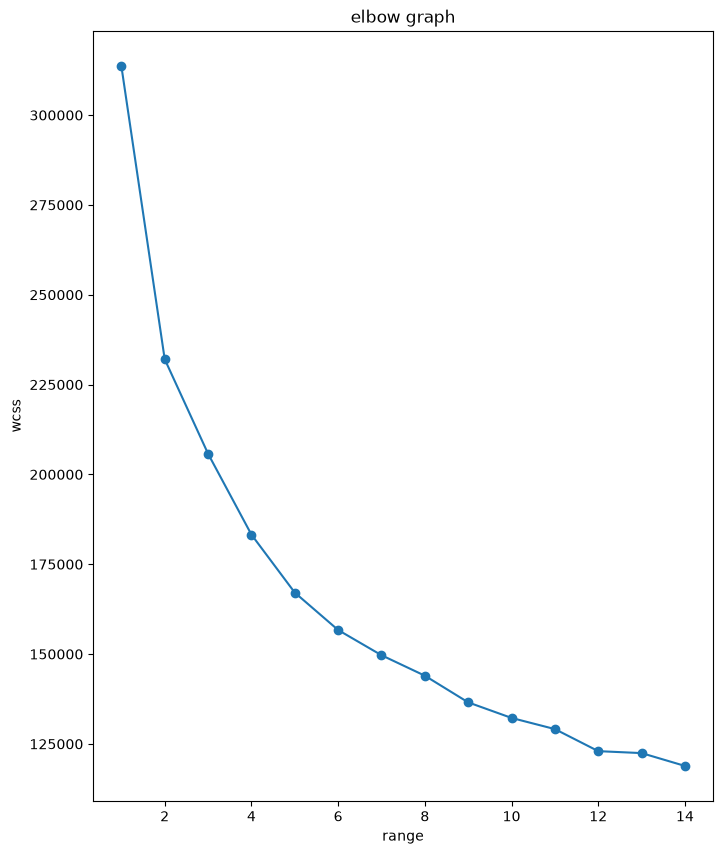

In [97]:
plt.figure(figsize  = (8,10)) 
plt.plot(range(1,15),wcss,marker = 'o')
plt.title('elbow graph')
plt.ylabel('wcss')
plt.xlabel('range')
plt.show()

In [98]:
Striker_km = KMeans(n_clusters = 2)
Striker_km.fit(Striker_1)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",2
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",None
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](2, 23)"

In [99]:
G = Striker_km.predict(Striker_1)
G

array([1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0,
       1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1,
       1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1,
       1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       1, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0,
       1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0,
       0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1,
       0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1,
       1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0,
       1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0,
       1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1,
       1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 1,
       1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 1,

In [100]:
labels = Striker_km.labels_
labels

array([1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0,
       1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1,
       1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1,
       1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       1, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0,
       1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0,
       0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1,
       0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1,
       1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0,
       1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0,
       1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1,
       1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 1,
       1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 1,

In [101]:
Striker_1['Clusters'] = labels
Striker_1.head()

,Footedness,Marital Status,Goals Scored,Assists,Shots on Target,Shot Accuracy,Conversion Rate,Dribbling Success,Movement off the Ball,Hold-up Play,...,Penalty Success Rate,Impact on Team Performance,Off-field Conduct,total contribution,Nationality_Brazil,Nationality_England,Nationality_France,Nationality_Germany,Nationality_Spain,Clusters
0,0,0,17.483571,10.778533,34.795488,0.677836,0.166241,0.757061,50.921924,71.806409,...,0.922727,8.570370,11.451388,116.882195,0,0,0,0,1,1
1,0,1,14.308678,13.728250,31.472436,0.544881,0.192774,0.796818,61.396150,53.726866,...,0.678984,3.444638,8.243689,113.521571,0,0,1,0,0,1
2,0,0,18.238443,3.804297,25.417413,0.518180,0.160379,0.666869,65.863945,60.452227,...,0.843858,8.429491,9.506835,96.556476,0,0,0,1,0,1
3,1,0,22.615149,9.688908,20.471443,0.599663,0.184602,0.638776,88.876877,60.511979,...,0.662997,6.532552,8.199653,126.859035,0,0,1,0,0,0
4,0,1,13.829233,6.048072,29.887563,0.582982,0.105319,0.591485,75.565531,54.982158,...,0.906538,8.414915,6.665333,110.548681,0,0,1,0,0,1


In [102]:
round(Striker_1.groupby('Clusters')['total contribution'].mean(), 2)

Clusters
0    126.68
1    105.09
Name: total contribution, dtype: float64

In [103]:
mapping = {1:'Best strikers', 0:'Regular strikers'}
Striker_1['Strikers types'] = Striker_1['Clusters'].map(mapping)
Striker_1

,Footedness,Marital Status,Goals Scored,Assists,Shots on Target,Shot Accuracy,Conversion Rate,Dribbling Success,Movement off the Ball,Hold-up Play,...,Impact on Team Performance,Off-field Conduct,total contribution,Nationality_Brazil,Nationality_England,Nationality_France,Nationality_Germany,Nationality_Spain,Clusters,Strikers types
0,0,0,17.483571,10.778533,34.795488,0.677836,0.166241,0.757061,50.921924,71.806409,...,8.570370,11.451388,116.882195,0,0,0,0,1,1,Best strikers
1,0,1,14.308678,13.728250,31.472436,0.544881,0.192774,0.796818,61.396150,53.726866,...,3.444638,8.243689,113.521571,0,0,1,0,0,1,Best strikers
2,0,0,18.238443,3.804297,25.417413,0.518180,0.160379,0.666869,65.863945,60.452227,...,8.429491,9.506835,96.556476,0,0,0,1,0,1,Best strikers
3,1,0,22.615149,9.688908,20.471443,0.599663,0.184602,0.638776,88.876877,60.511979,...,6.532552,8.199653,126.859035,0,0,1,0,0,0,Regular strikers
4,0,1,13.829233,6.048072,29.887563,0.582982,0.105319,0.591485,75.565531,54.982158,...,8.414915,6.665333,110.548681,0,0,1,0,0,1,Best strikers
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,0,1,17.694550,7.156699,39.042650,0.707015,0.240660,0.707748,89.351540,60.284576,...,5.999478,12.419711,137.714664,0,1,0,0,0,0,Regular strikers
496,1,1,9.813769,13.393060,39.430525,0.597348,0.186052,0.725775,78.155010,39.221882,...,5.967767,8.653989,134.059548,0,0,0,1,0,0,Regular strikers
497,0,1,14.048307,9.922529,33.458564,0.511813,0.186012,0.575824,69.519115,56.797022,...,11.249112,6.329751,160.843475,0,1,0,0,0,0,Regular strikers
498,1,1,10.621909,6.286463,32.168438,0.583693,0.239519,0.733418,68.168495,76.433782,...,1.452370,11.305826,110.450232,0,1,0,0,0,1,Best strikers


In [104]:
Striker_1 = Striker_1.drop('Clusters', axis = 1)
Striker_1.head()

,Footedness,Marital Status,Goals Scored,Assists,Shots on Target,Shot Accuracy,Conversion Rate,Dribbling Success,Movement off the Ball,Hold-up Play,...,Penalty Success Rate,Impact on Team Performance,Off-field Conduct,total contribution,Nationality_Brazil,Nationality_England,Nationality_France,Nationality_Germany,Nationality_Spain,Strikers types
0,0,0,17.483571,10.778533,34.795488,0.677836,0.166241,0.757061,50.921924,71.806409,...,0.922727,8.570370,11.451388,116.882195,0,0,0,0,1,Best strikers
1,0,1,14.308678,13.728250,31.472436,0.544881,0.192774,0.796818,61.396150,53.726866,...,0.678984,3.444638,8.243689,113.521571,0,0,1,0,0,Best strikers
2,0,0,18.238443,3.804297,25.417413,0.518180,0.160379,0.666869,65.863945,60.452227,...,0.843858,8.429491,9.506835,96.556476,0,0,0,1,0,Best strikers
3,1,0,22.615149,9.688908,20.471443,0.599663,0.184602,0.638776,88.876877,60.511979,...,0.662997,6.532552,8.199653,126.859035,0,0,1,0,0,Regular strikers
4,0,1,13.829233,6.048072,29.887563,0.582982,0.105319,0.591485,75.565531,54.982158,...,0.906538,8.414915,6.665333,110.548681,0,0,1,0,0,Best strikers


In [105]:
L = Striker_1.isna().sum()
Striker_1

,Footedness,Marital Status,Goals Scored,Assists,Shots on Target,Shot Accuracy,Conversion Rate,Dribbling Success,Movement off the Ball,Hold-up Play,...,Penalty Success Rate,Impact on Team Performance,Off-field Conduct,total contribution,Nationality_Brazil,Nationality_England,Nationality_France,Nationality_Germany,Nationality_Spain,Strikers types
0,0,0,17.483571,10.778533,34.795488,0.677836,0.166241,0.757061,50.921924,71.806409,...,0.922727,8.570370,11.451388,116.882195,0,0,0,0,1,Best strikers
1,0,1,14.308678,13.728250,31.472436,0.544881,0.192774,0.796818,61.396150,53.726866,...,0.678984,3.444638,8.243689,113.521571,0,0,1,0,0,Best strikers
2,0,0,18.238443,3.804297,25.417413,0.518180,0.160379,0.666869,65.863945,60.452227,...,0.843858,8.429491,9.506835,96.556476,0,0,0,1,0,Best strikers
3,1,0,22.615149,9.688908,20.471443,0.599663,0.184602,0.638776,88.876877,60.511979,...,0.662997,6.532552,8.199653,126.859035,0,0,1,0,0,Regular strikers
4,0,1,13.829233,6.048072,29.887563,0.582982,0.105319,0.591485,75.565531,54.982158,...,0.906538,8.414915,6.665333,110.548681,0,0,1,0,0,Best strikers
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,0,1,17.694550,7.156699,39.042650,0.707015,0.240660,0.707748,89.351540,60.284576,...,0.770213,5.999478,12.419711,137.714664,0,1,0,0,0,Regular strikers
496,1,1,9.813769,13.393060,39.430525,0.597348,0.186052,0.725775,78.155010,39.221882,...,0.876903,5.967767,8.653989,134.059548,0,0,0,1,0,Regular strikers
497,0,1,14.048307,9.922529,33.458564,0.511813,0.186012,0.575824,69.519115,56.797022,...,0.747261,11.249112,6.329751,160.843475,0,1,0,0,0,Regular strikers
498,1,1,10.621909,6.286463,32.168438,0.583693,0.239519,0.733418,68.168495,76.433782,...,0.799489,1.452370,11.305826,110.450232,0,1,0,0,0,Best strikers


In [106]:
x = Striker_1.drop(['Strikers types'],axis  = 1)
y = Striker_1['Strikers types']
print(x.shape)
print(y.shape)

(500, 23)
(500,)


In [107]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

In [108]:
scaler = StandardScaler()
scaler_x = scaler.fit_transform(x)
scaler_x

array([[-1.07047781, -1.03252879,  0.50002889, ..., -0.47801802,
        -0.47169258,  1.86125917],
       [-1.07047781,  0.968496  , -0.14874861, ...,  2.09197134,
        -0.47169258, -0.53727069],
       [-1.07047781, -1.03252879,  0.65428418, ..., -0.47801802,
         2.12002488, -0.53727069],
       ...,
       [-1.07047781,  0.968496  , -0.20195464, ..., -0.47801802,
        -0.47169258, -0.53727069],
       [ 0.93416229,  0.968496  , -0.90212639, ..., -0.47801802,
        -0.47169258, -0.53727069],
       [-1.07047781, -1.03252879, -1.4203297 , ..., -0.47801802,
        -0.47169258, -0.53727069]], shape=(500, 23))

In [109]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(scaler_x,y,test_size = 0.2, random_state = 42)
x_train.shape

(400, 23)

In [110]:
#model training
lgr_model = LogisticRegression(max_iter=1000)
lgr_model.fit(x_train,y_train)
#prediction
lgr_pre_model = lgr_model.predict(x_test)

#accuracy
accuracy = accuracy_score(y_test,lgr_pre_model)
print(accuracy*100,'%')
accuracy



98.0 %


0.98

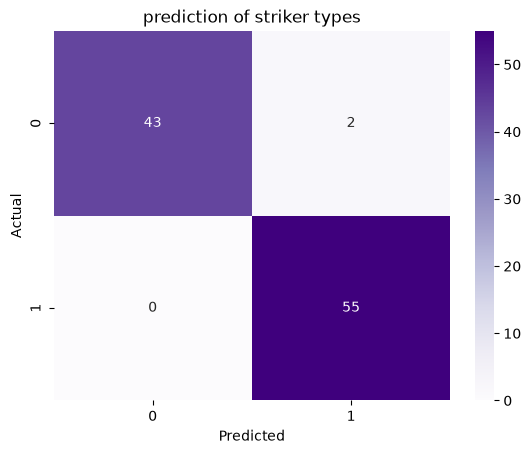

,0,1
0,43,2
1,0,55


In [111]:
confusion = confusion_matrix(y_test,lgr_pre_model)
sns.heatmap(confusion,annot = True, fmt = "d",cmap = "Purples")
plt.title('prediction of striker types')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()
confusion = pd.DataFrame(confusion)
confusion

In [112]:
Striker_1['Strikers types'].value_counts()

Strikers types
Regular strikers    270
Best strikers       230
Name: count, dtype: int64

In [113]:
model = LinearRegression()
model.fit(df[["WorkHoursPerWeek"]],df["StressLevel"])

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[-0.]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['WorkHoursPerWeek']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,5.49
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [114]:
prediction = model.predict(df[["WorkHoursPerWeek"]])
print(prediction)

[5.41972193 5.43505183 5.4385895  ... 5.44448561 5.44330639 5.41382582]


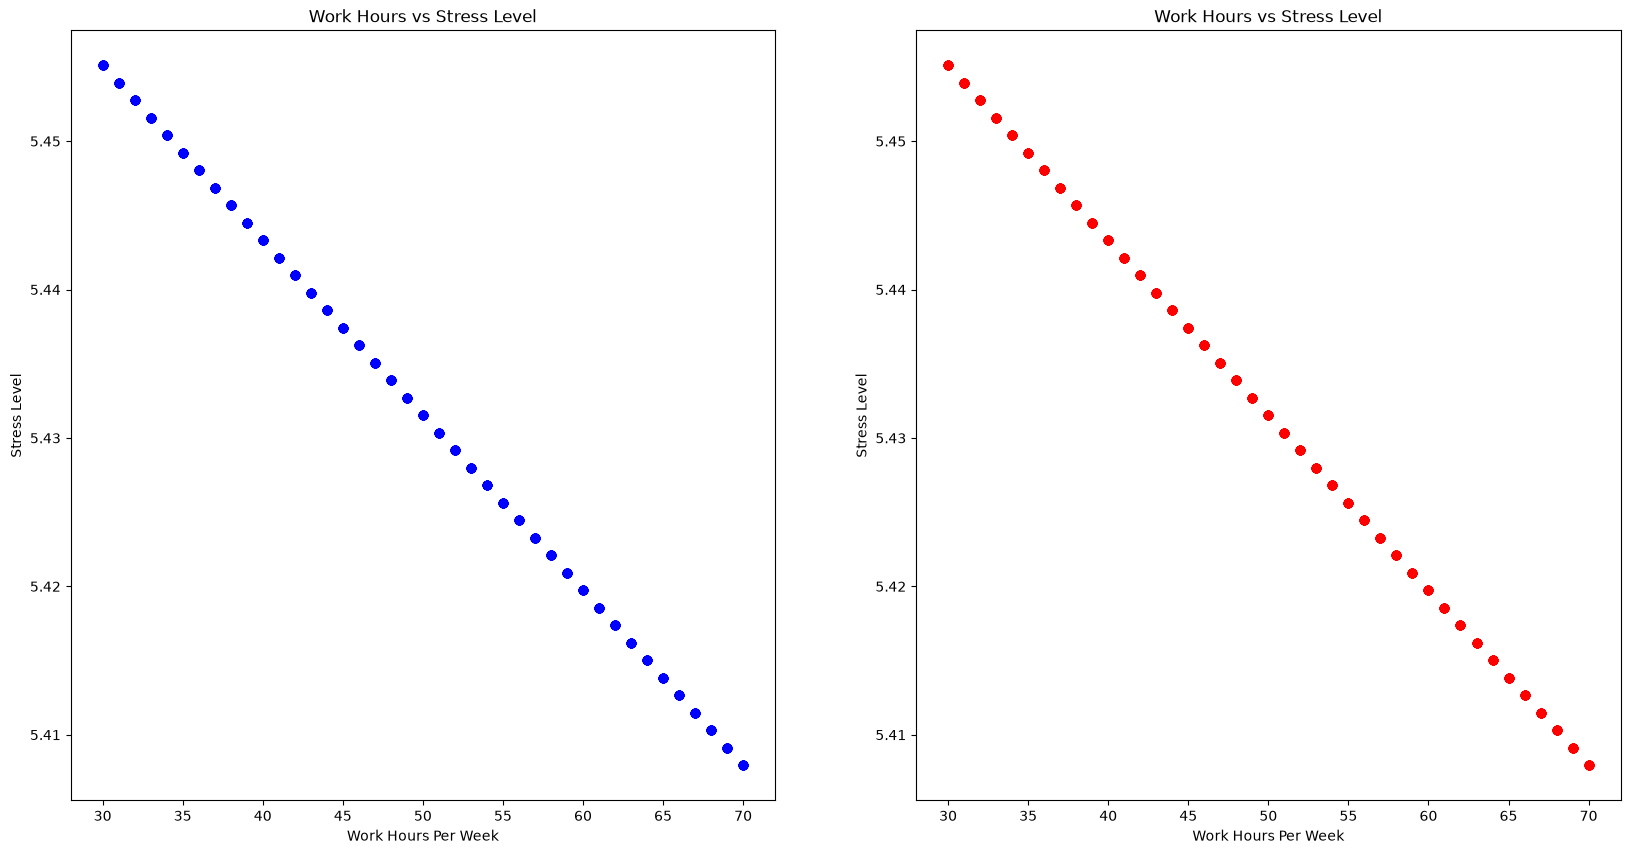

In [115]:
male = df["Gender"] == "Male"
female = df["Gender"] == "Female"
plt.figure(figsize = (20,10))
plt.subplot(1,2,1)

plt.scatter(df.loc[male, "WorkHoursPerWeek"],prediction[male], color = "blue")

plt.xlabel("Work Hours Per Week")
plt.ylabel("Stress Level")
plt.title("Work Hours vs Stress Level")

plt.subplot(1,2,2)

plt.scatter(df.loc[female, "WorkHoursPerWeek"],prediction[female], color = "red")

plt.xlabel("Work Hours Per Week")
plt.ylabel("Stress Level")
plt.title("Work Hours vs Stress Level")

plt.show()

In [116]:
data.groupby("department")["Task Completion Rates"].describe()

,count,mean,std,min,25%,50%,75%,max
department,,,,,,,,
Engineering,6.0,77.500000,9.874209,70.0,70.00,72.5,86.25,90.0
Finance,7.0,75.000000,9.574271,65.0,65.00,80.0,82.50,85.0
Human Resources,6.0,73.333333,10.327956,60.0,65.00,80.0,80.00,80.0
Marketing,6.0,80.833333,8.612007,70.0,73.75,85.0,85.00,90.0
Sales,6.0,80.000000,8.366600,75.0,75.00,75.0,82.50,95.0


In [117]:
data

,EmployeeID,gender,department,Days Present,Accuracy of Work,Meeting Project Deadlines,Task Completion Rates,Interpersonal Skills Rating,Decision-Making Skills Rating,Sales Revenue Generated,churned,Interpersonal Skills Rating_sqrt
0,1,1,Sales,20,High,Yes,85,8,7,51638,No,2.828427
1,2,0,Marketing,22,Medium,Yes,90,7,6,97797,Yes,2.645751
2,3,1,Human Resources,25,High,No,80,9,8,95341,No,3.000000
3,4,1,Engineering,19,Low,Yes,75,6,5,91806,No,2.449490
4,5,0,Finance,23,Medium,Yes,85,7,7,64247,Yes,2.645751
5,6,1,Sales,21,High,Yes,95,8,8,89988,No,2.828427
6,7,0,Marketing,24,Low,No,70,5,4,70934,Yes,2.236068
7,8,1,Human Resources,18,Medium,Yes,80,6,6,96578,No,2.449490
8,9,1,Engineering,20,High,Yes,90,8,7,74219,No,2.828427
9,10,0,Finance,22,Medium,Yes,85,7,6,87009,Yes,2.645751


In [118]:
data['Sales Revenue Generated'] = data['Sales Revenue Generated'].astype(int)
print(data['Sales Revenue Generated'].dtype)

int64


In [119]:
LR = LinearRegression()
LR.fit(data[["Decision-Making Skills Rating"]],data["Task Completion Rates"])

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[4.9]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Decision-Making Skills Rating']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,46.12
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [120]:
pred = LR.predict(data[["Decision-Making Skills Rating"]])
pred

array([80.41919806, 75.51944107, 85.31895504, 70.61968408, 80.41919806,
       85.31895504, 65.7199271 , 75.51944107, 80.41919806, 75.51944107,
       85.31895504, 70.61968408, 80.41919806, 85.31895504, 65.7199271 ,
       75.51944107, 80.41919806, 75.51944107, 85.31895504, 70.61968408,
       80.41919806, 85.31895504, 65.7199271 , 75.51944107, 80.41919806,
       70.61968408, 80.41919806, 85.31895504, 65.7199271 , 75.51944107,
       80.41919806])

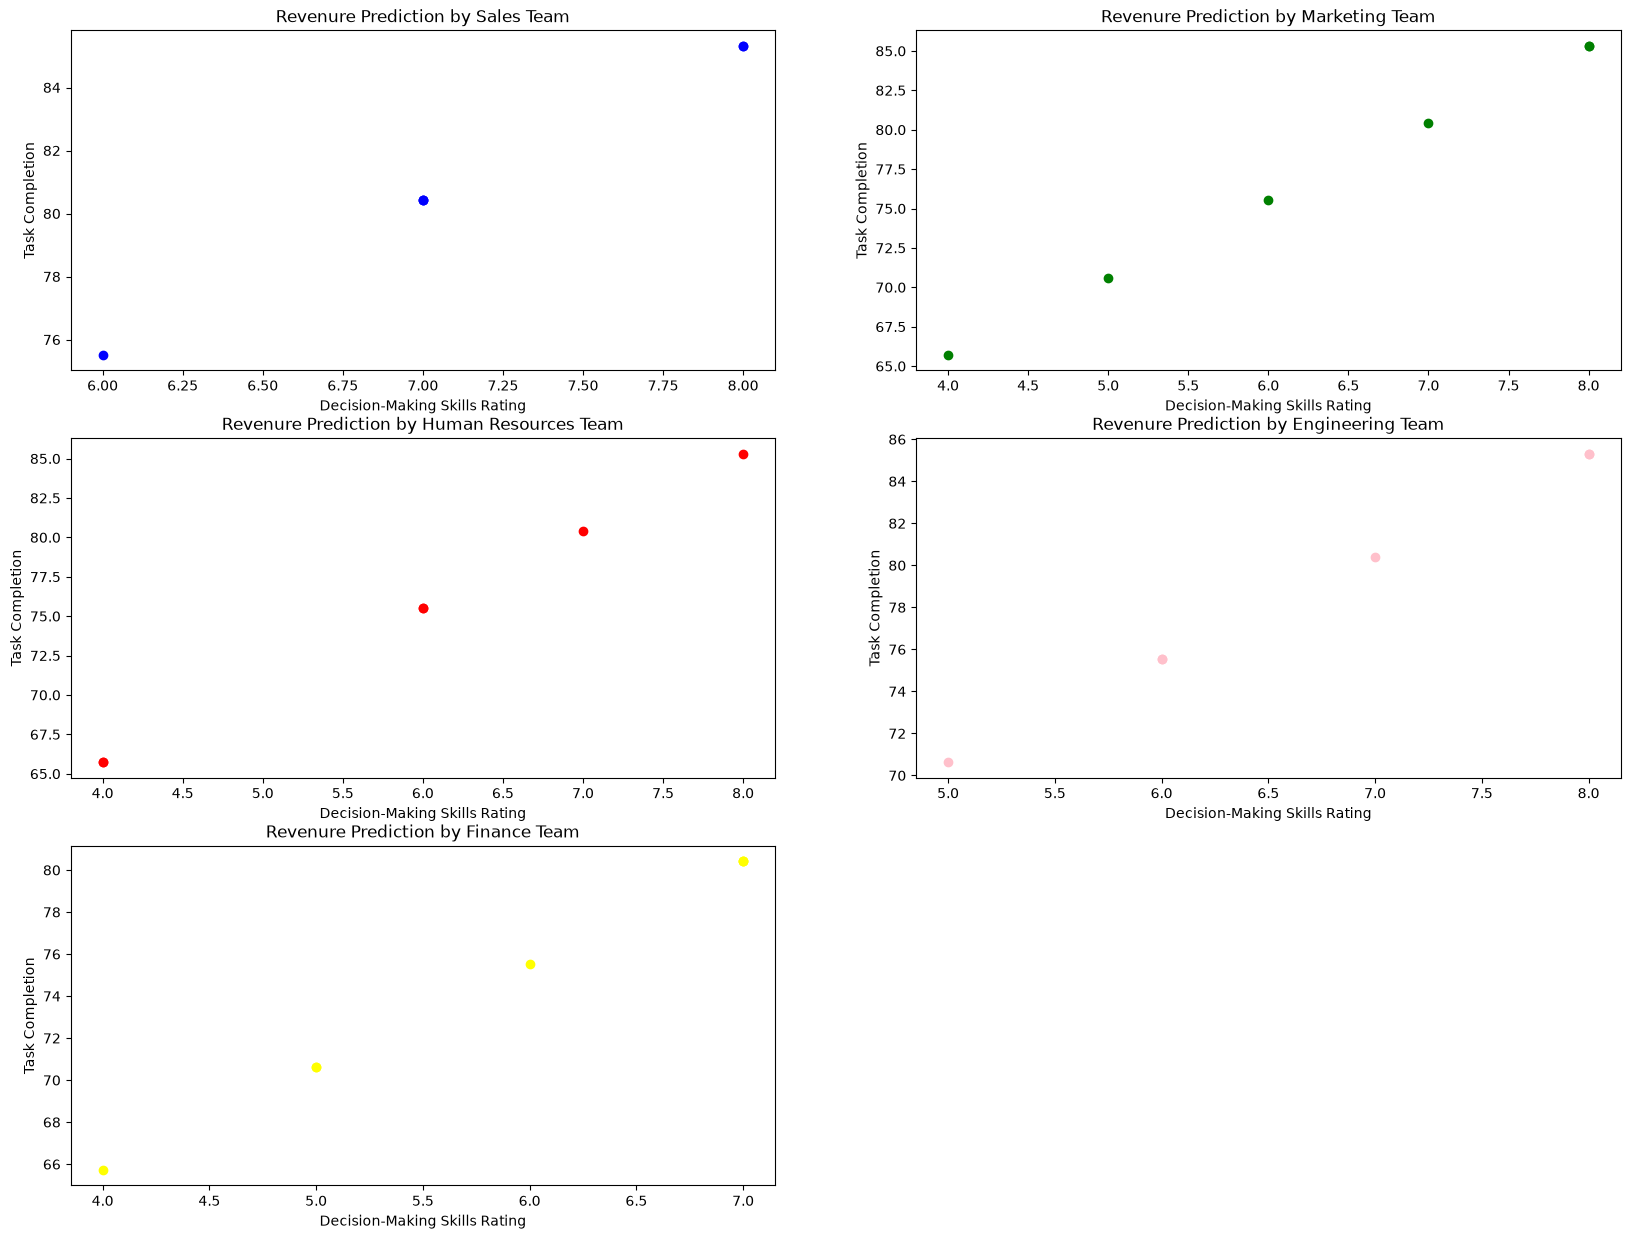

In [121]:
Sales= data['department'] == "Sales"
Marketing = data['department'] == "Marketing"
Human_Resources = data['department'] == "Human Resources"
Engineering = data['department'] == "Engineering"
Finance = data['department'] == "Finance"
plt.figure(figsize = (20,15))
plt.subplot(3,2,1)
plt.scatter(data.loc[Sales,"Decision-Making Skills Rating"],pred[Sales],color  = "blue")
plt.xlabel("Decision-Making Skills Rating")
plt.ylabel("Task Completion")
plt.title("Revenure Prediction by Sales Team")

plt.subplot(3,2,2)
plt.scatter(data.loc[Marketing,"Decision-Making Skills Rating"],pred[Marketing],color  = "green")
plt.xlabel("Decision-Making Skills Rating")
plt.ylabel("Task Completion")
plt.title("Revenure Prediction by Marketing Team")

plt.subplot(3,2,3)
plt.scatter(data.loc[Human_Resources,"Decision-Making Skills Rating"],pred[Human_Resources],color  = "red")
plt.xlabel("Decision-Making Skills Rating")
plt.ylabel("Task Completion")
plt.title("Revenure Prediction by Human Resources Team")

plt.subplot(3,2,4)
plt.scatter(data.loc[Engineering,"Decision-Making Skills Rating"],pred[Engineering],color  = "pink")
plt.xlabel("Decision-Making Skills Rating")
plt.ylabel("Task Completion")
plt.title("Revenure Prediction by Engineering Team")

plt.subplot(3,2,5)
plt.scatter(data.loc[Finance,"Decision-Making Skills Rating"],pred[Finance],color  = "yellow")
plt.xlabel("Decision-Making Skills Rating")
plt.ylabel("Task Completion")
plt.title("Revenure Prediction by Finance Team")
plt.show()





In [122]:
data.groupby("gender")["Sales Revenue Generated"].describe()

,count,mean,std,min,25%,50%,75%,max
gender,,,,,,,,
0,13.0,76925.615385,12674.215929,57836.0,70934.0,75795.0,81770.00,97797.0
1,18.0,73808.611111,16016.000463,51638.0,62885.0,76002.0,88925.25,96578.0


In [130]:
data["Decision-Making Skills Rating"].corr(
    data["Task Completion Rates"])

np.float64(0.7081517741584236)

In [131]:
x = pd.get_dummies(
    data[["department", "Decision-Making Skills Rating"]],
    columns=["department"],
    dtype=int
)

y = data["Task Completion Rates"]

LR.fit(x, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](6,)","[ 5.02,-1.31, 0.25,-1.3 , 3.69,-1.32]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](6,)","['Decision-Making Skills Rating','department_Engineering', 'department_Finance','department_Human Resources','department_Marketing', 'department_Sales']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,45.38
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,6
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)


In [1]:
#hypothetical prediction 
new_data = pd.DataFrame({
    "department": [
        "Sales", "Sales", "Sales",
        "Marketing", "Marketing", "Marketing",
        "Human Resources", "Human Resources", "Human Resources",
        "Engineering", "Engineering", "Engineering",
        "Finance", "Finance", "Finance"
    ],
    "Decision-Making Skills Rating": [12, 13, 14] * 5
})

new_X = pd.get_dummies(new_data, columns = ["department"], dtype = int)

new_X = new_X.reindex(columns = x.columns,fill_value = 0)
new_data["Predicted Task Completion"] = LR.predict(new_X)
print(new_data)

NameError: name 'pd' is not defined

In [ ]:
Sales = new_data['department'] == "Sales"
Marketing = new_data['department'] == "Marketing"
Human_Resources = new_data['department'] == "Human Resources"
Engineering = new_data['department'] == "Engineering"
Finance = new_data['department'] == "Finance"

plt.figure(figsize=(20,15))

plt.subplot(3,2,1)
plt.scatter(new_data.loc[Sales, "Decision-Making Skills Rating"],
            new_data.loc[Sales, "Predicted Task Completion"], color="blue")
plt.xlabel("Decision-Making Skills Rating")
plt.ylabel("Predicted Task Completion")
plt.title("Task Completion Prediction by Sales Team")

plt.subplot(3,2,2)
plt.scatter(new_data.loc[Marketing, "Decision-Making Skills Rating"],
            new_data.loc[Marketing, "Predicted Task Completion"], color="green")
plt.xlabel("Decision-Making Skills Rating")
plt.ylabel("Predicted Task Completion")
plt.title("Task Completion Prediction by Marketing Team")

plt.subplot(3,2,3)
plt.scatter(new_data.loc[Human_Resources, "Decision-Making Skills Rating"],
            new_data.loc[Human_Resources, "Predicted Task Completion"], color="red")
plt.xlabel("Decision-Making Skills Rating")
plt.ylabel("Predicted Task Completion")
plt.title("Task Completion Prediction by Human Resources Team")

plt.subplot(3,2,4)
plt.scatter(new_data.loc[Engineering, "Decision-Making Skills Rating"],
            new_data.loc[Engineering, "Predicted Task Completion"], color="pink")
plt.xlabel("Decision-Making Skills Rating")
plt.ylabel("Predicted Task Completion")
plt.title("Task Completion Prediction by Engineering Team")

plt.subplot(3,2,5)
plt.scatter(new_data.loc[Finance, "Decision-Making Skills Rating"],
            new_data.loc[Finance, "Predicted Task Completion"], color="orange")
plt.xlabel("Decision-Making Skills Rating")
plt.ylabel("Predicted Task Completion")
plt.title("Task Completion Prediction by Finance Team")

plt.tight_layout()
plt.show()